# Model Training

Train LinearSVC and Logistic Regression on `peakflo_features.parquet`.
Data is split randomly into train / test (80 / 20).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

SEED = 42
df = pd.read_parquet("peakflo_features.parquet")
df.shape

(4894, 11)

## 1. Split

Plain random 80/20 split.

In [2]:
TARGET = "accountName"
FEATURES = ["text", "vendorId", "log_amount", "is_neg"]

train, test = train_test_split(df, test_size=0.2, random_state=SEED)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"train={len(train)}  test={len(test)}")

train=3915  test=979


## 2. Features

Text -> TF-IDF on words (phrases) and character chunks (typos). Vendor -> one-hot. Amount -> scaled.
Everything is fitted on train only, inside the pipeline.

In [3]:
def make_features():
    return ColumnTransformer([
        ("words", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "text"),
        ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "text"),
        ("vendor", OneHotEncoder(handle_unknown="ignore"), ["vendorId"]),
        ("amount", StandardScaler(), ["log_amount", "is_neg"]),
    ])

## 3. Train

LinearSVC is fast and strong on sparse text. Logistic Regression gives probabilities; `class_weight="balanced"` boosts rare classes.

In [4]:
models = {
    "LinearSVC": make_pipeline(make_features(), LinearSVC(C=0.5, max_iter=3000, random_state=SEED)),
    "LogReg": make_pipeline(make_features(), LogisticRegression(C=20, class_weight="balanced", max_iter=500, random_state=SEED)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:10s} test={model.score(X_test, y_test):.3f}")

/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC  test=0.884
LogReg     test=0.867


## 4. Hyperparameter tuning (5-fold cross-validation)

Search LinearSVC settings with 5-fold CV on the training set only. The test set is used once at the end.

In [6]:
from sklearn.model_selection import GridSearchCV, KFold

params = {
    "linearsvc__C": [0.1, 0.3, 0.5, 1, 2],
    "columntransformer__chars__ngram_range": [(2, 5), (1, 6)],
}

search = GridSearchCV(
    make_pipeline(make_features(), LinearSVC(max_iter=5000, random_state=SEED)),
    params,
    cv=KFold(5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)
search.fit(X_train, y_train)  # train only, test stays untouched

print("best params:", search.best_params_)
print(f"CV accuracy: {search.best_score_:.3f}")
print(f"test accuracy: {search.score(X_test, y_test):.3f}")

/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zeltrox/Docume

best params: {'columntransformer__chars__ngram_range': (2, 5), 'linearsvc__C': 2}
CV accuracy: 0.866
test accuracy: 0.889


/home/zeltrox/Documents/peakflo/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## 5. Most common test errors (LinearSVC)

In [7]:
pred = models["LinearSVC"].predict(X_test)
errors = pd.DataFrame({"true": y_test, "predicted": pred})[y_test != pred]

print(f"wrong: {len(errors)}/{len(test)}")
errors.value_counts().head(12)

wrong: 114/979


true                                         predicted                                  
132098 IC Clearing account - Paid on Behalf  132098 IC Clearing account                     18
134001 Prepaid Operating Expense             611202 Online Subscription/Tool                 9
611202 Online Subscription/Tool              134001 Prepaid Operating Expense                7
132098 IC Clearing account                   134001 Prepaid Operating Expense                3
134004 Prepaid Subscription                  611202 Online Subscription/Tool                 3
132098 IC Clearing account                   132098 IC Clearing account - Paid on Behalf     2
611202 Online Subscription/Tool              134004 Prepaid Subscription                     2
619209 Others                                619205 Repairs and Maintenance                  2
619201 Equipment Expense                     611202 Online Subscription/Tool                 2
612002 Paid Search                           132098 IC C

## 6. Classification report + confusion matrix (LinearSVC, test)

The matrix shows only the 8 biggest test classes; 103x103 is unreadable.

                                             precision    recall  f1-score   support

     131011 Advance to Supplier - Companies       0.00      0.00      0.00         1
                131020 Unbilled receivables       1.00      1.00      1.00         5
                 132098 IC Clearing account       0.82      0.94      0.87       137
132098 IC Clearing account - Paid on Behalf       0.60      0.22      0.32        27
           134001 Prepaid Operating Expense       0.67      0.71      0.69        41
                   134002 Prepaid Insurance       0.80      0.67      0.73         6
                        134003 Prepaid Rent       0.00      0.00      0.00         0
                134004 Prepaid Subscription       0.50      0.33      0.40         6
           141001 Computer Equipment - Cost       0.89      0.89      0.89         9
             142101 Office Equipment - Cost       0.67      0.67      0.67         3
                   145001 Renovation - Cost       0.00      0.00

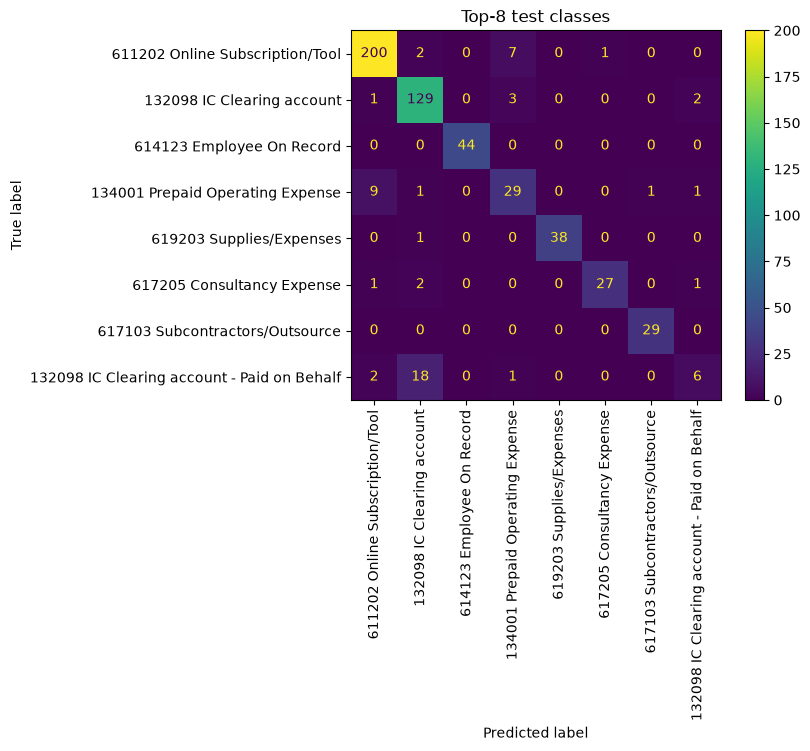

In [8]:
print(classification_report(y_test, pred, zero_division=0))

top8 = y_test.value_counts().head(8).index
mask = y_test.isin(top8)
ConfusionMatrixDisplay.from_predictions(y_test[mask], pred[mask], labels=top8, xticks_rotation=90)
plt.title("Top-8 test classes")
plt.show()

## 7. Save the model

Save the final LinearSVC pipeline (features + model in one file) with `joblib`, plus a small JSON with its details.
Then load it back to check it gives the same predictions.

In [9]:
import json
from datetime import date
from pathlib import Path

import joblib
import sklearn

Path("models").mkdir(exist_ok=True)
final = models["LinearSVC"]
joblib.dump(final, "models/linear_svc.joblib")

meta = {
    "model": "LinearSVC",
    "target": TARGET,
    "features": FEATURES,
    "test_accuracy": round(final.score(X_test, y_test), 4),
    "sklearn_version": sklearn.__version__,
    "saved_on": str(date.today()),
}
Path("models/linear_svc.json").write_text(json.dumps(meta, indent=2))
print(meta)

# Load it back and check the predictions are identical
loaded = joblib.load("models/linear_svc.joblib")
print("same predictions after reload:", (loaded.predict(X_test) == pred).all())

{'model': 'LinearSVC', 'target': 'accountName', 'features': ['text', 'vendorId', 'log_amount', 'is_neg'], 'test_accuracy': 0.8836, 'sklearn_version': '1.9.1', 'saved_on': '2026-10-11'}
same predictions after reload: True
